# The mtDSB oligodendrocyte signature in situ: human MS and Baló sections on Xenium 5k

The human single-nucleus atlases did not show the mtDSB-specific markers in MS OLs (analysis/16), but they pool
whole tissue blocks per sample, so a localised response would be diluted. The human CNS Xenium 5k run (office Mac,
`/Volumes/moldiassd/human_MS_Balo`, clustered h5ad) has four sections imaged with the same technology as the mouse
data: **S07-256 and S13-019** (MS; cross-sections that look like spinal cord or brainstem) and **Balo-1, Balo-2**
(Baló concentric sclerosis). There is no pathology annotation and no control tissue, so the comparison is **within
section**: OLs in demyelinated white matter vs OLs in myelinated white matter of the same section.

* **A.** Zones from local myelin RNA (`utils/lesion_zones.py`); grey matter (neuron-rich neighbourhoods) excluded.
* **B.** OL expression by zone: mtDSB-specific markers, the shared stress arm, interferon, hypoxia; neighbouring
  non-OL cells as the spill-over control.
* **C.** Per-cell rates with spatial block-bootstrap CIs.
* **D.** The tissue border: a confound, and the comparison that removes it.
* **E.** The gradient with myelin loss (away from the border), and maps.

Input: `results/human_xenium/cells.csv.gz` (`scripts/export_human_xenium_cells.py`). OLs = Leiden (res. 1) clusters
0, 1, 2, 4 (SOX10+), OPCs = 18, 22 (PDGFRA+ OLIG2+), from marker means per cluster (section A). ATF5 is not on the
human panel.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
REPO = Path.cwd().resolve().parent; sys.path.insert(0, str(REPO))
from utils import lesion_zones as lz

OUT = REPO / "results" / "human_xenium"; FIG = OUT / "figures"; TAB = OUT / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
cells = pd.read_csv(OUT / "cells.csv.gz")
OL_CL, OPC_CL = {0, 1, 2, 4}, {18, 22}
cells["cls"] = np.where(cells.leiden_1.isin(OL_CL), "OL", np.where(cells.leiden_1.isin(OPC_CL), "OPC", "other"))
SECTIONS = ["S07-256", "S13-019", "Balo-1", "Balo-2"]
MYELIN = ["MOG", "MBP", "MAG", "CNP", "MOBP"]
SPECIFIC = ["TRIB3", "GDF15", "EIF4EBP1"]
SHARED = ["CDKN1A", "BBC3", "SESN2", "GADD45A", "DDIT3", "ATF4"]
IFN = ["IRF1", "STAT1", "CD74", "SERPINA3", "HLA-B"]
HYPOXIA = ["BNIP3", "SLC2A1", "VEGFA", "HIF1A", "HMOX1"]
OLGENES = ["MOG", "OPALIN", "SOX10", "OLIG2"]
ZONES = ["myelinated", "edge", "demyelinated"]

INK2, AXIS = "#52514e", "#c3c2b7"
BLUE, ORANGE, GREY, RED = "#2a78d6", "#eb6834", "#b8b7b0", "#d62728"
plt.rcParams.update({"axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlelocation": "left"})
def save(fig, name, dpi=200):
    fig.savefig(FIG / f"{name}.png", dpi=dpi, bbox_inches="tight"); fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
def save_table(df, name, index=True):
    df.to_csv(TAB / f"{name}.csv", index=index); return df
mk = ["MOG", "MBP", "SOX10", "OLIG2", "PDGFRA", "GFAP", "AQP4", "P2RY12", "CD68", "SNAP25", "CLDN5", "PTPRC", "CD3E"]
markers = (cells[mk].div(cells.total_counts.clip(lower=1), axis=0) * 1e3).groupby(cells.leiden_1).mean().round(1)
markers["n"] = cells.groupby("leiden_1").size()
save_table(markers, "cluster_markers")
display(markers.sort_values("SOX10", ascending=False).head(10))

,MOG,MBP,SOX10,OLIG2,PDGFRA,GFAP,AQP4,P2RY12,CD68,SNAP25,CLDN5,PTPRC,CD3E,n
leiden_1,,,,,,,,,,,,,,
18,0.3,9.8,3.6,2.4,2.5,31.8,0.5,0.0,0.1,0.5,0.0,0.0,0.0,5789
4,0.0,17.7,3.3,0.0,0.1,3.7,0.1,0.1,0.0,0.0,0.0,0.0,0.0,15087
1,6.7,23.4,3.2,0.4,0.0,14.3,0.3,0.0,0.0,0.0,0.0,0.0,0.0,22936
0,3.9,28.2,2.9,0.4,0.0,49.1,0.8,0.1,0.1,0.2,0.1,0.0,0.0,26624
22,0.4,7.7,2.4,3.4,2.4,5.8,0.5,0.0,0.1,2.2,0.0,0.0,0.0,2439
2,6.5,26.1,1.9,1.4,0.0,9.3,0.6,0.0,0.1,1.2,0.0,0.0,0.0,20355
8,0.3,36.7,0.3,0.1,0.1,84.8,0.9,0.2,0.2,0.2,0.2,0.4,0.1,13156
9,0.0,2.4,0.2,0.0,2.1,1.8,0.0,0.0,0.1,0.0,0.1,0.1,0.1,12425
21,0.2,6.3,0.2,0.1,0.1,16.5,0.3,0.0,0.0,2.9,0.2,0.0,0.0,3865


## A. Zones from local myelin RNA

cls                        OL   OPC  other
sample_id zone                            
Balo-1    demyelinated      6     1   1945
          edge             26    14    633
          grey matter    5110  1172  20980
          myelinated      198    35    833
Balo-2    demyelinated     32    15    814
          edge           1514   110   5016
          grey matter    6566   760  13890
          myelinated     6981   417   4653
S07-256   demyelinated   3235   116  22047
          edge          11623   728  20823
          grey matter    1275   192   3096
          myelinated    18219  1549  26915
S13-019   demyelinated   1401   104  16922
          edge           8375   947  17051
          grey matter    3257   275   4409
          myelinated    17184  1793  21215

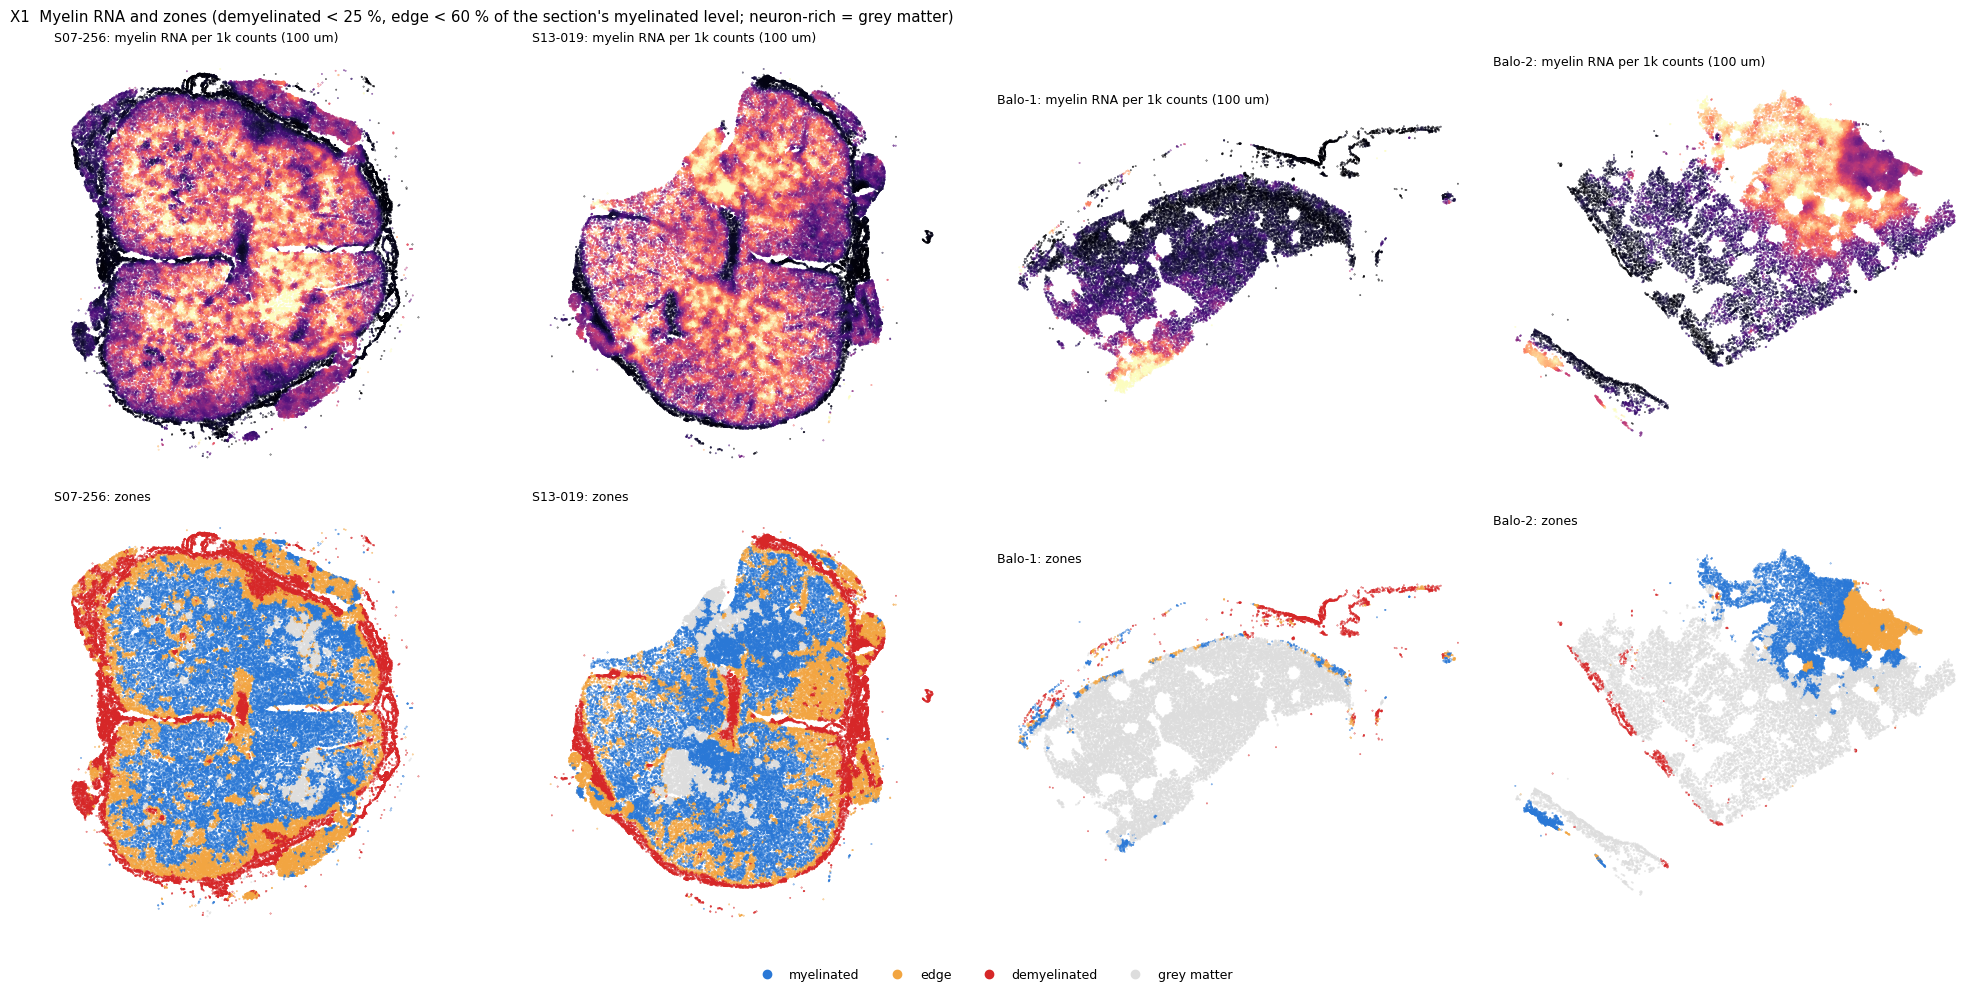

In [2]:
parts = []
for s in SECTIONS:
    d = cells[cells.sample_id == s].copy()
    d["myelin_local"] = lz.local_density(d, MYELIN, radius=100)
    d["neuron_local"] = lz.local_density(d, ["SNAP25"], radius=100)
    d["zone"] = lz.assign_zones(d.myelin_local.to_numpy(), d.neuron_local.to_numpy(), gm_max=1.0)
    ref = np.percentile(d.myelin_local[d.zone != "grey matter"], 90)
    d["myelin_rel"] = d.myelin_local / ref
    d["d_border"] = lz.border_distance(d)
    parts.append(d)
cells = pd.concat(parts)
cells[["sample_id", "cell_id", "myelin_local", "neuron_local", "myelin_rel", "d_border", "zone"]].round(4).to_csv(OUT / "zones.csv.gz", index=False)
ztab = save_table(pd.crosstab([cells.sample_id, cells.zone], cells.cls), "cells_by_zone")
display(ztab)
ZCOL = {"myelinated": "#2a78d6", "edge": "#f2a541", "demyelinated": "#d62728", "grey matter": "#dddddd"}
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for j, s in enumerate(SECTIONS):
    d = cells[cells.sample_id == s]
    ax = axes[0, j]
    sc = ax.scatter(d.x_centroid, d.y_centroid, c=d.myelin_local, s=0.08, cmap="magma", vmax=np.percentile(d.myelin_local, 98), rasterized=True)
    ax.set_title(f"{s}: myelin RNA per 1k counts (100 um)", fontsize=9); ax.set_aspect("equal"); ax.invert_yaxis(); ax.axis("off")
    ax = axes[1, j]
    ax.scatter(d.x_centroid, d.y_centroid, c=d.zone.map(ZCOL), s=0.08, rasterized=True)
    ax.set_title(f"{s}: zones", fontsize=9); ax.set_aspect("equal"); ax.invert_yaxis(); ax.axis("off")
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=z) for z, c in ZCOL.items()]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False)
fig.suptitle("X1  Myelin RNA and zones (demyelinated < 25 %, edge < 60 % of the section's myelinated level; neuron-rich = grey matter)", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0.04, 1, 1)); save(fig, "X1_zones", dpi=120)

**A.** In S07-256 and S13-019 the myelinated tissue is central and a myelin-poor band runs along the rim, typical of
subpial demyelination in MS spinal cord / brainstem. The Baló sections are largely neuron-rich, so most of their
low-myelin tissue is grey matter and is excluded; Balo-2 keeps a myelinated region with an edge and a small
demyelinated white-matter area, Balo-1 very little white matter. The main results therefore come from the two MS
sections; the Baló sections are reported but thin.

## B. OL expression by zone, with neighbouring cells as the spill-over control

section  Balo-2      S07-256            S13-019      
zone       edge demyelinated  edge demyelinated  edge
gene                                                 
BBC3       0.85         1.66  0.73         2.40  1.06
CDKN1A     1.92         1.80  1.34         2.27  1.34
EIF4EBP1   1.57         0.54  0.36         1.44  0.64
GDF15      0.42         1.54  0.48         3.10  0.56
MOG        0.02        -2.26 -0.65        -2.57 -0.55
OPALIN    -0.08        -2.22 -0.66        -4.16 -1.14
SESN2      0.65         0.64  0.15         1.04  0.42
SOX10     -0.20        -0.04 -0.16         0.11 -0.10
TRIB3     -0.14         1.27  0.82         1.45  0.82

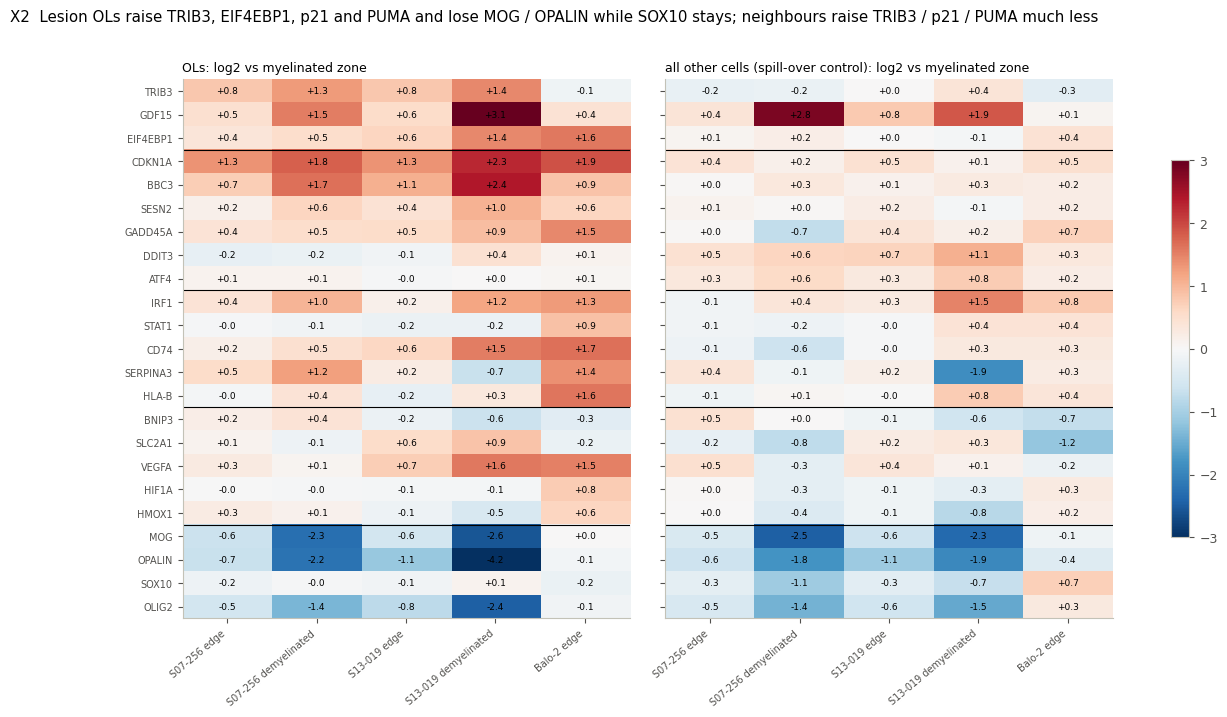

In [3]:
GENES = SPECIFIC + SHARED + IFN + HYPOXIA + OLGENES
def per10k(d):
    return d[GENES].sum() / max(d.total_counts.sum(), 1) * 1e4
rows = []
for s in SECTIONS:
    for cls in ("OL", "other"):
        d = cells[(cells.sample_id == s) & (cells.cls == cls)]
        base = per10k(d[d.zone == "myelinated"])
        for z in ("edge", "demyelinated"):
            dz = d[d.zone == z]
            if len(dz) < 100: continue
            lfc = np.log2((per10k(dz) + 0.05) / (base + 0.05))
            rows += [{"section": s, "cells": cls, "zone": z, "gene": g, "log2_vs_myelinated": lfc[g], "n": len(dz)} for g in GENES]
bz = save_table(pd.DataFrame(rows).round(3), "log2_by_zone", index=False)
cols = [(s, z) for s in SECTIONS for z in ("edge", "demyelinated") if ((bz.section == s) & (bz.zone == z) & (bz.cells == "OL")).any()]
fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"wspace": 0.08})
for ax, cls in zip(axes, ("OL", "other")):
    H = pd.DataFrame({f"{s} {z}": bz[(bz.section == s) & (bz.zone == z) & (bz.cells == cls)].set_index("gene").log2_vs_myelinated for s, z in cols}).reindex(GENES)
    im = ax.imshow(H, cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
    for i in range(H.shape[0]):
        for j in range(H.shape[1]):
            v = H.iat[i, j]
            if pd.notna(v): ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=6.5)
    ax.set_xticks(range(H.shape[1]), H.columns, rotation=40, ha="right", fontsize=7)
    ax.set_yticks(range(len(GENES)), GENES if ax is axes[0] else [], fontsize=7)
    for y in np.cumsum([len(SPECIFIC), len(SHARED), len(IFN), len(HYPOXIA)]) - 0.5: ax.axhline(y, color="k", lw=0.8)
    ax.set_title(f"{'OLs' if cls == 'OL' else 'all other cells (spill-over control)'}: log2 vs myelinated zone", fontsize=9)
fig.colorbar(im, ax=axes, shrink=0.7)
fig.suptitle("X2  Lesion OLs raise TRIB3, EIF4EBP1, p21 and PUMA and lose MOG / OPALIN while SOX10 stays; neighbours raise TRIB3 / p21 / PUMA much less", x=0.01, ha="left")
save(fig, "X2_zone_heatmap")
display(bz[(bz.cells == "OL") & bz.gene.isin(SPECIFIC + ["CDKN1A", "BBC3", "SESN2", "MOG", "OPALIN", "SOX10"])].pivot_table(index="gene", columns=["section", "zone"], values="log2_vs_myelinated").round(2))

**B.** In both MS sections, OLs in demyelinated white matter, compared with OLs in myelinated white matter of the same
section, show the mtDSB pattern:

* **mtDSB-specific markers up**: TRIB3 +1.3 / +1.4 log2, EIF4EBP1 +0.6 / +1.4, GDF15 +1.5 / +3.1.
* **p53 arm up**: CDKN1A (p21) +1.8 / +2.3, BBC3 (PUMA) +1.6 / +2.4, SESN2 +0.6 / +1.0, GADD45A +0.5 / +1.0.
* **Myelin genes down, lineage kept**: MOG -2.2 / -2.3, OPALIN -2.1 / -3.0, SOX10 unchanged (as in mtDSB, analysis/13).
* The edge zone is intermediate for all of these.
* But much of the demyelinated zone is a rim along the tissue border, so part of this contrast could be a border
  effect (section D).
* **Spill-over control**: other cells in the same zones change TRIB3, EIF4EBP1, CDKN1A and BBC3 little (about -0.2 to
  +0.3), so these rises are OL-intrinsic. GDF15 also rises in other cells (+1.9 / +2.8, likely macrophages), so for
  GDF15 the OL signal may be partly neighbours' RNA.
* Unlike mtDSB, IRF1 and CD74 also rise in lesion OLs (interferon / antigen presentation, as in EAE and the snRNA
  atlases), and hypoxia genes (BNIP3, SLC2A1) change inconsistently.

## C. Per-cell rates with spatial block-bootstrap CIs

rate_den  rate_num    ratio  \
section event                                                               
S07-256 TRIB3+                                  0.0026    0.0071   2.7560   
        EIF4EBP1+                               0.0151    0.0189   1.2447   
        GDF15+                                  0.0005    0.0043   7.8846   
        CDKN1A+                                 0.0482    0.1338   2.7743   
        BBC3+                                   0.0045    0.0151   3.3654   
        TRIB3 or EIF4EBP1 and CDKN1A or BBC3    0.0030    0.0090   3.0245   
S13-019 TRIB3+                                  0.0029    0.0100   3.5044   
        EIF4EBP1+                               0.0125    0.0271   2.1679   
        GDF15+                                  0.0003    0.0086  24.5310   
        CDKN1A+                                 0.0325    0.0928   2.8524   
        BBC3+                                   0.0051    0.0243   4.7934   
        TRIB3 or EIF4EBP1 and CDKN1A or BBC3    0.0017    0.0086   5.0754   

                                                ci_lo    ci_hi  n_num  
section event                                                          
S07-256 TRIB3+                                 1.7570   4.3671   3235  
        EIF4EBP1+                              0.9158   1.6478   3235  
        GDF15+                                 3.6133  19.4967   3235  
        CDKN1A+                                2.4449   3.2466   3235  
        BBC3+                                  2.2823   4.8638   3235  
        TRIB3 or EIF4EBP1 and CDKN1A or BBC3   1.9523   4.7561   3235  
S13-019 TRIB3+                                 1.8345   6.4493   1401  
        EIF4EBP1+                              1.4673   3.0462   1401  
        GDF15+                                10.2793  89.4506   1401  
        CDKN1A+                                2.2905   3.5082   1401  
        BBC3+                                  3.2824   7.3493   1401  
        TRIB3 or EIF4EBP1 and CDKN1A or BBC3   2.5712   9.2867   1401

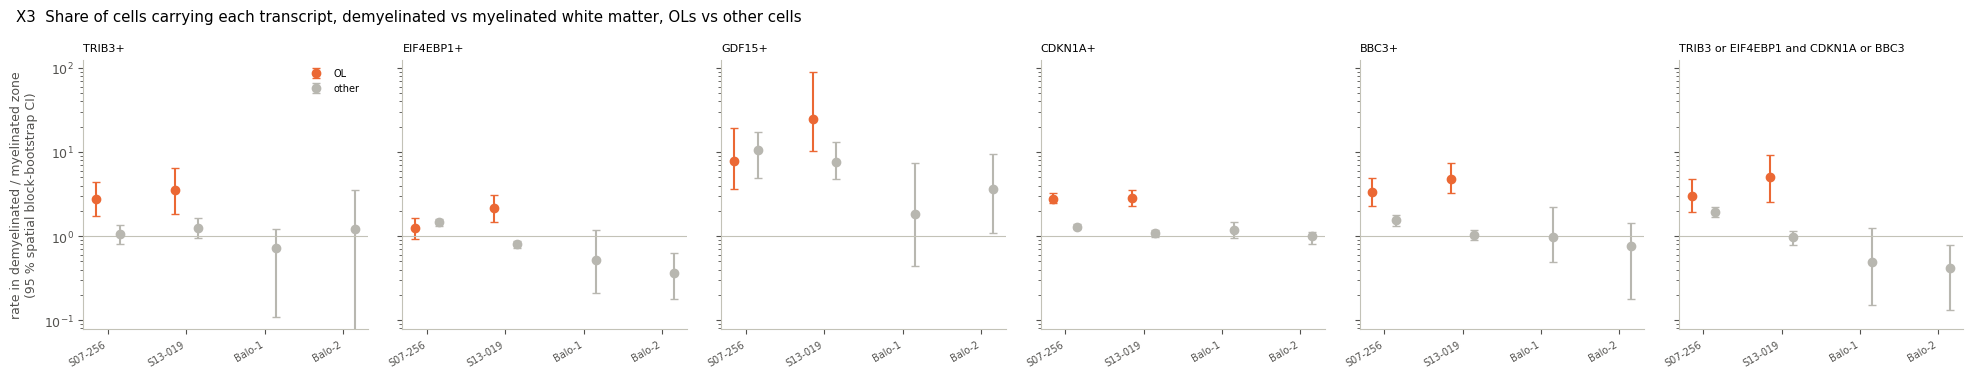

In [4]:
ol = cells[cells.cls == "OL"].copy()
oth = cells[cells.cls == "other"].copy()
EVENTS = {"TRIB3+": ["TRIB3"], "EIF4EBP1+": ["EIF4EBP1"], "GDF15+": ["GDF15"], "CDKN1A+": ["CDKN1A"], "BBC3+": ["BBC3"],
          "TRIB3 or EIF4EBP1 and CDKN1A or BBC3": None}
for d in (ol, oth):
    for e, g in EVENTS.items():
        d[e] = (d[g].sum(1) > 0) if g else ((d.TRIB3 + d.EIF4EBP1 > 0) & (d.CDKN1A + d.BBC3 > 0))
rows = []
for s in SECTIONS:
    for lab, d in (("OL", ol), ("other", oth)):
        ds = d[d.sample_id == s]
        for z in ("edge", "demyelinated"):
            if (ds.zone == z).sum() < 100: continue
            for e in EVENTS:
                r = lz.block_bootstrap_ratio(ds, e, "zone", z, "myelinated", n_boot=300)
                rows.append({"section": s, "cells": lab, "zone": z, "event": e, **r})
rates = save_table(pd.DataFrame(rows).round(4), "rates_block_bootstrap", index=False)
fig, axes = plt.subplots(1, len(EVENTS), figsize=(3.3 * len(EVENTS), 3.8), sharey=True)
for ax, e in zip(axes, EVENTS):
    t = rates[(rates.event == e) & (rates.zone == "demyelinated")]
    for k, (lab, col) in enumerate((("OL", ORANGE), ("other", GREY))):
        tt = t[t.cells == lab].set_index("section").reindex([s for s in SECTIONS if s in set(t.section)])
        x = np.arange(len(tt)) + (k - 0.5) * 0.3
        ax.errorbar(x, tt.ratio, yerr=[tt.ratio - tt.ci_lo, tt.ci_hi - tt.ratio], fmt="o", color=col, capsize=3, label=lab if e == list(EVENTS)[0] else None)
        ax.set_xticks(np.arange(len(tt)), tt.index, rotation=30, ha="right", fontsize=7)
    ax.axhline(1, color=AXIS, lw=0.8); ax.set_yscale("log"); ax.set_title(e, fontsize=8)
axes[0].set_ylabel("rate in demyelinated / myelinated zone\n(95 % spatial block-bootstrap CI)"); axes[0].legend(frameon=False, fontsize=7)
fig.suptitle("X3  Share of cells carrying each transcript, demyelinated vs myelinated white matter, OLs vs other cells", x=0.01, ha="left")
fig.tight_layout(); save(fig, "X3_rates")
display(rates[(rates.cells == "OL") & (rates.zone == "demyelinated")].set_index(["section", "event"])[["rate_den", "rate_num", "ratio", "ci_lo", "ci_hi", "n_num"]])

**C.** Per cell, the share of OLs carrying TRIB3 (2.8-3.5x), CDKN1A (2.8-2.9x) or BBC3 (3.4-4.8x) transcripts is
higher in demyelinated than in myelinated white matter in both MS sections, with block-bootstrap CIs excluding 1;
EIF4EBP1 only in S13-019. Other cells in the same zones rise far less (GDF15 excepted). Co-expression of an mtDSB-specific marker (TRIB3 or EIF4EBP1) with the p53 arm (CDKN1A or BBC3) in the
same OL is rare in myelinated tissue and enriched in lesions. Absolute rates are low (these transcripts are sparse in
human Xenium), and the Baló sections have too few white-matter OLs in lesion zones for firm estimates.

## D. The tissue border: a confound, and the comparison that removes it

TRIB3+  CDKN1A+  BBC3+  \
sample_id zone         band                                 
S07-256   demyelinated < 150 um      0.54    13.62   1.73   
                       150-400 um    1.08    13.72   1.58   
                       > 400 um      0.45    12.83   1.26   
          edge         < 150 um      0.98    16.32   1.10   
                       150-400 um    0.94    15.72   1.51   
                       > 400 um      0.52    10.29   0.73   
          myelinated   < 150 um      0.68    14.97   0.51   
                       150-400 um    1.08    13.48   1.75   
                       > 400 um      0.21     4.09   0.39   
S13-019   demyelinated < 150 um      0.84     7.80   2.51   
                       150-400 um    1.51     9.27   3.45   
                       > 400 um      0.69    10.21   1.56   
          edge         < 150 um      1.16    10.60   1.53   
                       150-400 um    1.18     8.96   1.27   
                       > 400 um      0.29     5.75   1.08   
          myelinated   < 150 um      1.43     6.45   1.43   
                       150-400 um    0.55     4.63   0.55   
                       > 400 um      0.22     3.00   0.47   

                                   TRIB3 or EIF4EBP1 and CDKN1A or BBC3   n_OL  
sample_id zone         band                                                     
S07-256   demyelinated < 150 um                                    0.76    925  
                       150-400 um                                  1.08   1203  
                       > 400 um                                    0.81   1107  
          edge         < 150 um                                    0.58   1734  
                       150-400 um                                  1.13   3181  
                       > 400 um                                    0.75   6708  
          myelinated   < 150 um                                    0.85    588  
                       150-400 um                                  1.62    742  
                       > 400 um                                    0.22  16889  
S13-019   demyelinated < 150 um                                    0.28    359  
                       150-400 um                                  0.65    464  
                       > 400 um                                    1.38    578  
          edge         < 150 um                                    1.02   1377  
                       150-400 um                                  0.45   2198  
                       > 400 um                                    0.33   4800  
          myelinated   < 150 um                                    1.08    558  
                       150-400 um                                  0.21   1448  
                       > 400 um                                    0.13  15178

rate_den  rate_num    ratio  \
section event                                                               
S07-256 TRIB3+                                  0.0021    0.0045   2.1795   
        CDKN1A+                                 0.0409    0.1283   3.1352   
        BBC3+                                   0.0039    0.0126   3.2362   
        TRIB3 or EIF4EBP1 and CDKN1A or BBC3    0.0022    0.0081   3.7111   
S13-019 TRIB3+                                  0.0022    0.0069   3.1830   
        CDKN1A+                                 0.0300    0.1021   3.3976   
        BBC3+                                   0.0047    0.0156   3.3287   
        TRIB3 or EIF4EBP1 and CDKN1A or BBC3    0.0013    0.0138  10.5038   

                                               ci_lo    ci_hi  n_num  n_den  
section event                                                                
S07-256 TRIB3+                                0.6322   4.6765   1107  16889  
        CDKN1A+                               2.5579   3.7632   1107  16889  
        BBC3+                                 1.8128   5.5564   1107  16889  
        TRIB3 or EIF4EBP1 and CDKN1A or BBC3  1.5778   7.0711   1107  16889  
S13-019 TRIB3+                                0.6900   6.6021    578  15178  
        CDKN1A+                               2.4414   4.2397    578  15178  
        BBC3+                                 1.4274   5.9722    578  15178  
        TRIB3 or EIF4EBP1 and CDKN1A or BBC3  3.0471  19.6472    578  15178

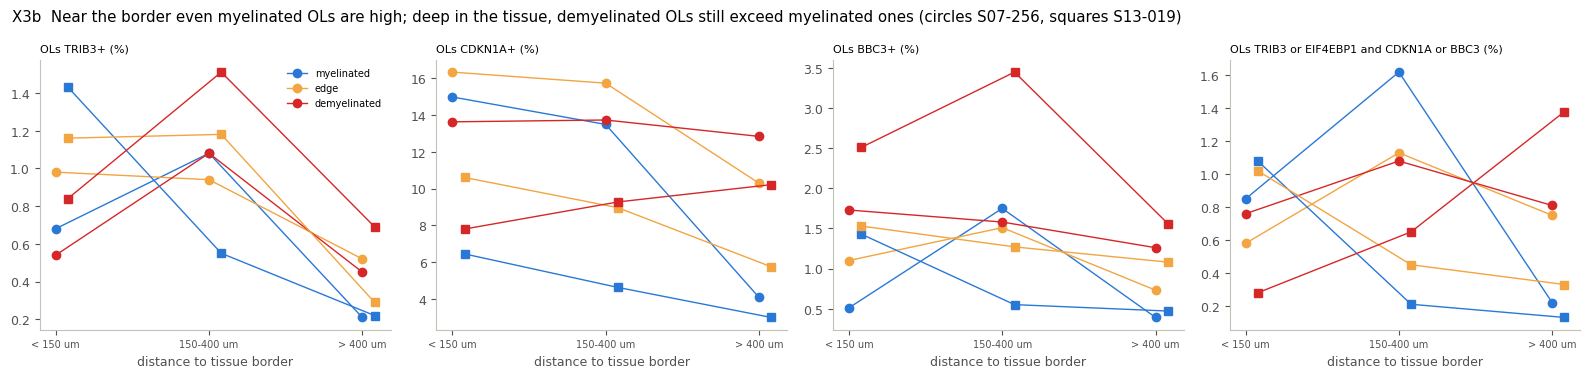

In [5]:
ol = ol.join(cells[["d_border"]], how="left") if "d_border" not in ol else ol
ol["band"] = pd.cut(ol.d_border, [-1, 150, 400, 1e9], labels=["< 150 um", "150-400 um", "> 400 um"])
EV4 = ["TRIB3+", "CDKN1A+", "BBC3+", "TRIB3 or EIF4EBP1 and CDKN1A or BBC3"]
strat = (ol[ol.sample_id.isin(["S07-256", "S13-019"]) & ol.zone.isin(ZONES)].groupby(["sample_id", "zone", "band"], observed=True)[EV4]
         .mean().mul(100).round(2))
strat["n_OL"] = ol[ol.sample_id.isin(["S07-256", "S13-019"]) & ol.zone.isin(ZONES)].groupby(["sample_id", "zone", "band"], observed=True).size()
strat = save_table(strat, "rates_by_zone_and_border_distance")
display(strat)
deep = ol[(ol.d_border > 400) & ol.zone.isin(ZONES)]
rows = []
for s in ["S07-256", "S13-019"]:
    for e in EV4:
        rows.append({"section": s, "event": e, **lz.block_bootstrap_ratio(deep[deep.sample_id == s], e, "zone", "demyelinated", "myelinated", n_boot=300)})
deep_r = save_table(pd.DataFrame(rows).round(4), "rates_deep_tissue_block_bootstrap", index=False)
display(deep_r.set_index(["section", "event"])[["rate_den", "rate_num", "ratio", "ci_lo", "ci_hi", "n_num", "n_den"]])
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=False)
for ax, e in zip(axes, EV4):
    for k, s in enumerate(["S07-256", "S13-019"]):
        t = strat.loc[s][e].unstack("band")
        for z, c_ in zip(ZONES, [BLUE, "#f2a541", RED]):
            if z in t.index:
                ax.plot(np.arange(3) + k * 0.08, t.loc[z].reindex(["< 150 um", "150-400 um", "> 400 um"]), marker="os"[k], color=c_, lw=1,
                        label=f"{z}" if (k == 0 and e == EV4[0]) else None)
    ax.set_xticks(range(3), ["< 150 um", "150-400 um", "> 400 um"], fontsize=7); ax.set_xlabel("distance to tissue border")
    ax.set_title(f"OLs {e} (%)", fontsize=8)
axes[0].legend(frameon=False, fontsize=7)
fig.suptitle("X3b  Near the border even myelinated OLs are high; deep in the tissue, demyelinated OLs still exceed myelinated ones (circles S07-256, squares S13-019)", x=0.01, ha="left")
fig.tight_layout(); save(fig, "X3b_border")

**D.** The tissue border is a major confound. Myelinated OLs within ~400 um of the border carry p21, PUMA and TRIB3
about as often as demyelinated OLs (e.g. S07-256, p21 in 13-15 % of OLs), while myelinated OLs deeper than 400 um are
low (p21 3-4 %). That border effect could be a section-edge artefact (damaged or degraded tissue at the cut) or real
subpial / meningeal pathology, which is common in MS spinal cord; these data cannot tell which. Restricting both
groups to OLs **deeper than 400 um from the border**, demyelinated OLs still exceed myelinated OLs in both sections
(p21 3.1-3.4x and PUMA 3.2-3.3x, CIs well above 1; an mtDSB-specific marker together with the p53 arm in the same
OL 3.7x and 10.5x, CIs 1.6-7.1 and 3.0-19.6). TRIB3 on its own is 2.2-3.2x but too sparse for its CI to exclude 1
(n = 578-1,107 deep demyelinated OLs).

## E. The gradient with myelin loss (away from the border), and maps

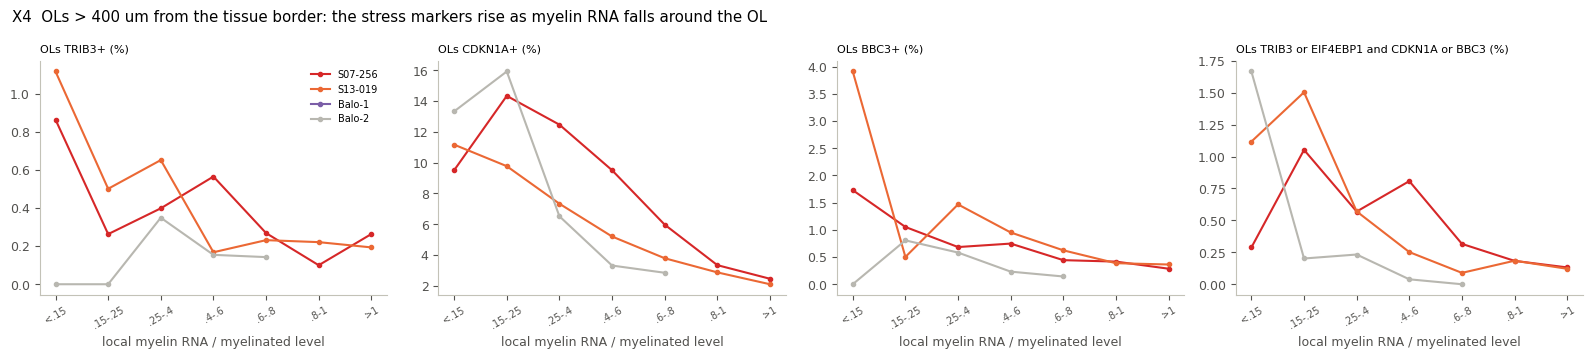

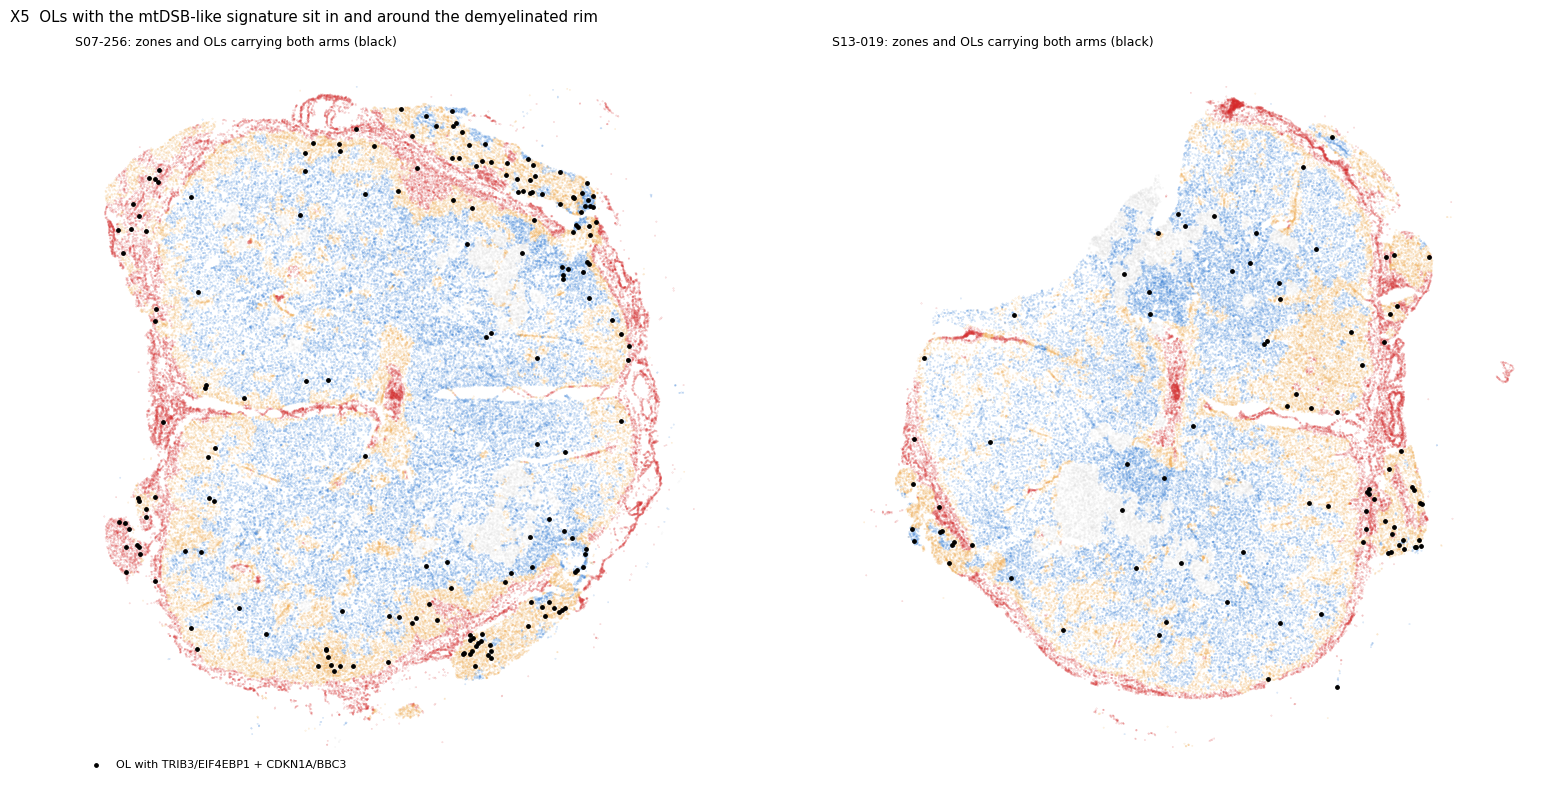

In [6]:
WM = ol[(ol.zone != "grey matter") & (ol.d_border > 400)].copy()
WM["bin"] = pd.cut(WM.myelin_rel.clip(upper=1.5), [0, 0.15, 0.25, 0.4, 0.6, 0.8, 1.0, 1.5], include_lowest=True)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharex=True)
for ax, e in zip(axes, ["TRIB3+", "CDKN1A+", "BBC3+", "TRIB3 or EIF4EBP1 and CDKN1A or BBC3"]):
    for s, c_ in zip(SECTIONS, [RED, ORANGE, "#7b5ea7", GREY]):
        t = WM[WM.sample_id == s].groupby("bin", observed=True)[e].agg(["mean", "size"])
        t = t[t["size"] >= 50]
        ax.plot(range(len(t)), 100 * t["mean"], marker="o", ms=3, color=c_, label=s)
    ax.set_xticks(range(7), ["<.15", ".15-.25", ".25-.4", ".4-.6", ".6-.8", ".8-1", ">1"], rotation=30, fontsize=7)
    ax.set_title(f"OLs {e} (%)", fontsize=8); ax.set_xlabel("local myelin RNA / myelinated level")
axes[0].legend(frameon=False, fontsize=7)
fig.suptitle("X4  OLs > 400 um from the tissue border: the stress markers rise as myelin RNA falls around the OL", x=0.01, ha="left")
fig.tight_layout(); save(fig, "X4_gradient")

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, s in zip(axes, ["S07-256", "S13-019"]):
    d = cells[cells.sample_id == s]
    ax.scatter(d.x_centroid, d.y_centroid, c=d.zone.map(ZCOL), s=0.05, alpha=0.35, rasterized=True)
    o = ol[(ol.sample_id == s) & ol["TRIB3 or EIF4EBP1 and CDKN1A or BBC3"]]
    ax.scatter(o.x_centroid, o.y_centroid, s=6, color="k", label="OL with TRIB3/EIF4EBP1 + CDKN1A/BBC3")
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.axis("off"); ax.set_title(f"{s}: zones and OLs carrying both arms (black)", fontsize=9)
axes[0].legend(frameon=False, loc="lower left", fontsize=8)
fig.suptitle("X5  OLs with the mtDSB-like signature sit in and around the demyelinated rim", x=0.01, ha="left")
fig.tight_layout(); save(fig, "X5_maps", dpi=150)

**E.** Away from the border (> 400 um), the share of OLs carrying TRIB3, CDKN1A or BBC3 still rises as local myelin RNA
falls, in both MS sections. On the maps, OLs carrying both arms cluster in the demyelinated rim and the edge zone
next to it, with only a few in the myelinated interior.

## Summary

* **In MS lesion white matter, OLs carry an mtDSB-like signature in situ**: compared with OLs in myelinated white matter
  of the same section, they raise TRIB3, EIF4EBP1, p21 and PUMA, lose MOG / OPALIN and keep SOX10, as mtDSB responder
  OLs do; neighbouring cells change these genes much less (GDF15 excepted).
* **The tissue border is a confound**: OLs near the section edge show the same stress transcripts even in myelinated
  tissue (artefact or subpial pathology, undetermined). Deep in the tissue (> 400 um), demyelinated OLs still carry
  p21 and PUMA ~3x and the combined mtDSB-specific + p53 signature 4-10x more often than myelinated OLs; TRIB3 alone is
  in the same direction but too sparse to be significant there.
* This **refines analysis/16**: the snRNA atlases, which pool whole blocks, did not show the specific markers, but a
  spatially resolved within-section comparison does. MS lesion OLs add an interferon / antigen-presentation component
  that mtDSB lacks.
* **What it does not show**: that mtDNA damage causes this state; it is compatible with mitochondrial injury in lesion
  OLs, as proposed for "hypoxia-like" (pattern III / Baló) lesions.
* **Caveats**: two MS sections (two donors), no pathology annotation (zones from myelin RNA), no control tissue,
  sparse transcripts per cell, and the Baló sections are mostly grey matter at this resolution (Balo-2 lesion edge:
  p21, EIF4EBP1 and PUMA up, TRIB3 not). Pathology-annotated lesions (LFB / MOG IHC, lesion activity, distance to the
  pia vs the cut edge) on more sections would make it firm.